# Incompressible LES: Pitz Daily with Extra Trees

## Preamble

In [1]:
# Standard Library
from pathlib import Path
from zipfile import ZipFile
import warnings

# Data and Numerical Computing
import gdown
import numpy as np

# FoamNordic
import foamnordic as fno

# Machine Learning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MaxAbsScaler, StandardScaler
from sklearn.ensemble import ExtraTreesRegressor

# Visualisation
import matplotlib.pyplot as plt
from IPython.display import display
import onsaemiro as osm

### Directories

In [2]:
# Case Type and Name
CASE_TYPE = "les"
CASE_NAME = "pitzDailySmag"
CATEGORY = "incompressible"

# FoamNordic Project Directory
PROJECT_DIR = Path.cwd().resolve()
BASE_DIR = next((path for path in (PROJECT_DIR, *PROJECT_DIR.parents) if (path / "tutorials" / "openfoam_tutorials").is_dir()), None)
if BASE_DIR is None:
    raise FileNotFoundError("Run this notebook from inside the FoamNordic source tree")

MAIN_DIR = BASE_DIR / "tutorials" / "foamnordic_tutorials" / CATEGORY
OF_SCRIPT_DIR = BASE_DIR / "tutorials" / "openfoam_tutorials" / CATEGORY / CASE_TYPE / CASE_NAME

# Output Directory
MODEL_DIR = MAIN_DIR / "model"
OUTPUT_DIR = MAIN_DIR / "output"
DATA_DIR = OUTPUT_DIR / "data"

for directory in [MODEL_DIR, OUTPUT_DIR, DATA_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

### Configuration

In [3]:
# DataGraph Configuration
FIG_X, FIG_Y = 3.5, 2.55
FIGURE_SIZE = (FIG_X, FIG_Y)
PALETTE = osm.get_palette("OKABE_ITO")
osm.set_style(figure_size=FIGURE_SIZE)

In [4]:
# Reproducibility
SEED = 42
N_TRAIN = 30000

In [5]:
# HPC configuration
ACCOUNT = "<allocation-account>" # e.g. project_xxxxxxx
PARTITION = "small"
TIME = "00:15:00"
N_NODES = 1
N_TASKS = 1
CPUS_PER_TASK = 1
MEM_PER_CPU = "2G"

# FoamNordic Slurm configuration
of_scheduler = fno.Slurm.openfoam(
    nodes=N_NODES,
    ntasks=N_TASKS,
    cpus_per_task=CPUS_PER_TASK,
    mem_per_cpu=MEM_PER_CPU,
)

model_scheduler = fno.Slurm.model(
    cpus_per_task=1,
    mem_per_cpu=MEM_PER_CPU,
)

scheduler = fno.Slurm(
    account=ACCOUNT,
    partition=PARTITION,
    time=TIME,
    openfoam=of_scheduler,
    model=model_scheduler,
)

## Extra Trees Closure

### Data

In [6]:
# Download the prepared LES data
DATA_ID = "1Kcanmq9og6a8Dy4EDWZSQJyceaQlASTD"
DATA_URL = f"https://drive.google.com/uc?id={DATA_ID}"
DATA_ARCHIVE = OUTPUT_DIR / "pitz_daily_smag_data.zip"
DATA_FILES = (
    "X_train.npy",
    "y_train.npy",
    "X_val.npy",
    "y_val.npy",
    "X_test.npy",
    "y_test.npy",
)

if not all((DATA_DIR / filename).is_file() for filename in DATA_FILES):
    gdown.download(
        url=DATA_URL,
        output=str(DATA_ARCHIVE),
        quiet=False,
    )

    with ZipFile(DATA_ARCHIVE) as archive:
        archive.extractall(DATA_DIR)

# Load the training, validation, and test splits
X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")
X_test = np.load(DATA_DIR / "X_test.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

# Select a deterministic training subset
if len(X_train) > N_TRAIN:
    random_generator = np.random.default_rng(seed=SEED)
    train_indices = random_generator.choice(len(X_train), size=N_TRAIN, replace=False)
    X_train = X_train[train_indices]
    y_train = y_train[train_indices]

In [7]:
# Scale the inputs and target
X_scaler = StandardScaler()
y_scaler = MaxAbsScaler()

X_train = X_scaler.fit_transform(X_train)
X_val = X_scaler.transform(X_val)
X_test = X_scaler.transform(X_test)

y_train = y_scaler.fit_transform(y_train.reshape(-1, 1)).ravel()
y_val = y_scaler.transform(y_val.reshape(-1, 1)).ravel()
y_test = y_scaler.transform(y_test.reshape(-1, 1)).ravel()

y_test_true = y_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

In [8]:
# FoamNordic export configuration
inputs = {
    "velocity_grad": fno.Tensor.tensor(components=9, dtype="float64"),
    "delta": fno.Tensor.scalar(dtype="float64"),
}

outputs = {
    "nut": fno.Tensor.scalar(dtype="float64"),
}

### Model Training

In [9]:
# Extra Trees Regressor
et = ExtraTreesRegressor(n_estimators=16, random_state=SEED, n_jobs=-1)
et.fit(X_train, y_train)

# Extra Trees prediction
y_test_pred_scaled = et.predict(X_test)

y_test_true = y_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
y_test_pred = y_scaler.inverse_transform(y_test_pred_scaled.reshape(-1, 1)).ravel()

et_mse = mean_squared_error(y_test_true, y_test_pred)
et_mae = mean_absolute_error(y_test_true, y_test_pred)
et_r2 = r2_score(y_test_true, y_test_pred)

print(f"MSE: {et_mse:.4e}")
print(f"MAE: {et_mae:.4e}")
print(f"R2: {et_r2:.4f}")

MSE: 3.2101e-11
MAE: 1.2558e-06
R2: 0.9501


### Model Export

In [10]:
# Export the Extra Trees model
MODEL_PATH = MODEL_DIR / "extra_trees_forest.fnom"

fno.Export.sklearn(
    model=et,
    path=MODEL_PATH,
    inputs=inputs,
    outputs=outputs,
    name="extra_trees",
    x_scaler=X_scaler,
    y_scaler=y_scaler,
    backend="forest",
    runtime="sklearn",
    input_format="numpy",
    verbose=True,
);

Property,Value
Artifact,extra_trees_forest.fnom
Payload,embedded .cpp
Format,Compiled + FNOM
Runtime,forest
Dtype,float64
Input format,numpy
Inputs,"velocity_grad[9], delta[1]"
Outputs,nut[1]
Input scaler,standard
Output scaler,maxabs


### Closure

In [11]:
# Define the learned Smagorinsky closure
closure = fno.Closure(
    name="nutFjord",
    operator=fno.Operator.model(path=MODEL_PATH),
    inputs={
        "velocity_grad": fno.Field.grad(value="U"),
        "delta": fno.Field.delta(),
    },
    outputs={
        "nut": fno.Field(name="nut"),
    },
    key=None,
)

### Case Definition

In [12]:
# Initialise the OpenFOAM case
case = fno.OpenFOAM.Case(
    name="pitzDailySmag-ExtraTrees",
    case_dir=OF_SCRIPT_DIR,
    run_dir=OUTPUT_DIR,
    of_cmd="module load openfoam/2512",
    shell="bash",
    application="pimpleFoam",
    ranks=N_TASKS,
    integration=None,
)

case.initialize(
    ranks=N_TASKS,
    mesh="blockMesh",
    validate_mesh=True,
);

### Observation Definition

In [13]:
# Define live field observations
observations = fno.Observe(
    summaries={
        "U": ("l2",),
        "nut": ("min", "max", "mean"),
    },
    interval=1,
)

### Submit Job

In [14]:
# Connect the OpenFOAM case and Slurm scheduler
longship = fno.Longship(
    case=case,
    closures=(closure,),
    transforms=(),
    observations=(observations,),
    placement=fno.Attached(model_cpus_per_node=None, data_path="auto"),
    scheduler=scheduler,
    name=None,
    verbose=True,
    numerics="convenient",
)

# Submit the workload
run = longship.launch(
    readiness_timeout=120.0,
    termination_grace=30.0,
    orphan_timeout=30.0,
    start_timeout=900.0,
    verbose=None,
    profile_every=0,
    receive_memory_bytes=None,
)

Resource,OpenFOAM,Model,Allocation
Processes,1 tasks,1 host(s),1 node(s)
CPU,1 cores,1 cores,2 cores
Memory,2 GiB,2 GiB,4.03125 GiB
Field programs,-,1,1
SHM,-,~32 MiB,~32 MiB


[FoamNordic] Preparing mesh with blockMesh: pitzDailySmag-ExtraTrees
[FoamNordic] Mesh is ready: pitzDailySmag-ExtraTrees
[FoamNordic] Sailing submitted with Job ID: 1290045
[FoamNordic] Sailing has launched with Job ID: 1290045
[FoamNordic] Sailing started at: 2026-09-13T14:57:49
[FoamNordic] Sailing in background: pitzDailySmag-ExtraTrees


### Live Observation

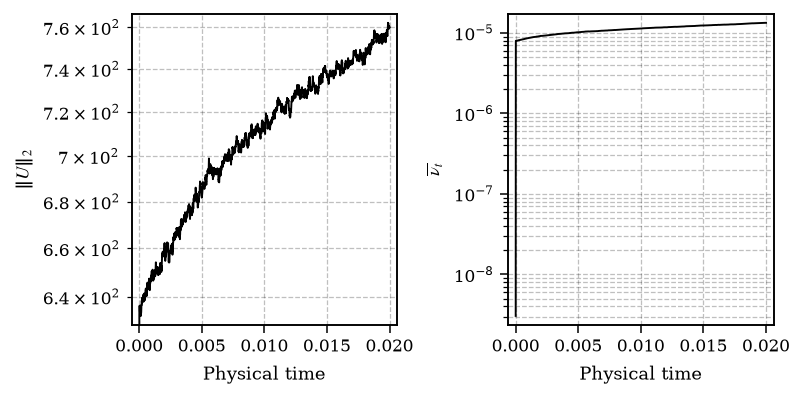

In [15]:
# Plot observations while the solver is running
records = []
figure, axes = plt.subplots(1, 2, figsize=(FIG_X * 1.5, FIG_Y), constrained_layout=True)
velocity_line, = axes[0].plot([], [], color="black")
nut_line, = axes[1].plot([], [], color="black")

axes[0].set_xlabel("Physical time")
axes[0].set_ylabel(r"$\Vert U \Vert_2$")
axes[1].set_xlabel("Physical time")
axes[1].set_ylabel(r"$\overline{\nu_t}$")

display_handle = display(figure, display_id=True)

for axis in axes:
    axis.set_yscale("log")

for record in run.observe(poll_interval=0.1, progress=True):
    records.append(record)
    physical_time = [item.time for item in records]
    velocity_l2 = [item.summary["U"].l2 for item in records]
    nut_mean = [item.summary["nut"].mean for item in records]

    velocity_line.set_data(physical_time, velocity_l2)
    nut_line.set_data(physical_time, nut_mean)

    for axis in axes:
        axis.relim()

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        for axis in axes:
            axis.autoscale_view()

    for axis in axes:
        axis.grid(True, which="both", alpha=0.25)

    display_handle.update(figure)

plt.close(figure)

In [16]:
# Collect the completed result
result = run.stop(
    force=False,
    timeout=3600.0,
    progress=True,
)

result.summary(
    style="compact",
    display=True,
);

Job ID,Name,Status,Partition,Node,Elapsed
1290045,pitzDailySmag-ExtraTrees,succeeded,small,rc4130,00:03:23


### Post-processing

In [17]:
# Read the final fields
post = result.postprocess

velocity = post.field(
    name="U",
    time_idx=-1,
    physical_time=None,
)
pressure = post.field(
    name="p",
    time_idx=-1,
    physical_time=None,
)

print("U shape:", velocity.shape)
print("p shape:", pressure.shape)

statistics = post.statistics(
    fields=["U", "p", "nut"],
    time_idx=-1,
    physical_time=None,
    verbose=True,
)

U shape: (12225, 3)
p shape: (12225,)


Field,Min,Max,Mean,Std,RMS
U,3.134291e-02,1.306559e+01,6.353088e+00,2.617790e+00,6.871285e+00
p,-3.245550e+01,1.144620e+02,6.562947e+01,2.149066e+01,6.905849e+01
nut,2.908370e-09,4.230470e-04,1.332301e-05,2.947874e-05,3.234964e-05
